# IEEE-CIS — Graf Tabanlı Öznitelik Mühendisliği (sızıntısız pipeline)

Bu notebook, BankSim üzerinde kurulan sızıntısız protokolü gerçek bir e-ticaret
dolandırıcılık veri setine (IEEE-CIS, 590.540 işlem, %3.5 fraud) taşır.


| Deney | Bu notebook'ta |
|---|---|
| **Hedef sızıntısı** (`community_fraud_rate` tüm veriden hesaplanıyordu) | Tüm öznitelikler — graf, topluluk, fraud oranı, aggregate, imputasyon, kategorik kodlama — **her fold'un yalnızca eğitim kısmından** öğrenilir (Bölüm 5) |
| **Look-ahead bias** | Graf yalnızca eğitim işlemlerinden kurulur; test varlıkları grafa girmez |
| **Entity leakage** (aynı müşteri iki fold'da) | `card1` bazlı GroupKFold protokolü (Bölüm 9) |
| **Zamansal bütünlük** | Out-of-time bölme, `TransactionDT` %80 kesim (Bölüm 10) |
| **Sınıf dağılımının çarpıtılması** | Alt örneklem **rastgele**, stratifiye değil → prevalans korunur (Bölüm 3) |
| **Simülatör/veri artefaktı** (PaySim dersi) | Deney öncesi **artefakt denetimi**: tek öznitelik AUC taraması, kural dedektörü, dejenerasyon kontrolü (Bölüm 7) |
| **Graf katkısı belirsiz** | **Set D = A + yalnızca graf** ile saf katkı izole edilir |
| **İstatistiksel anlamlılık yok** | Fold bazlı eşleştirilmiş t-testi, Wilcoxon, Cohen's d (Bölüm 12) |
| **Metrikler eksik** | PR-AUC, FPR, precision@k, recall@k, confusion matrix (Bölüm 6) |
| **Öznitelik atıfı gösterilmemiş** | SHAP, kategori bazında katkı payı (Bölüm 13) |
| **Zaman karmaşıklığı ölçülmemiş** | Algoritma bazlı çıkarım süreleri, işlem/saniye verimi (Bölüm 14) |
| **"Gradient Augmented" terimi yanlış** | **Gradient Boosted Decision Trees** (histogram tabanlı uygulama) |
| **Tekrarlanabilirlik detayları eksik** | Tüm hiperparametreler belgelenir; sızıntı öz-testi (Bölüm 8) |

## Keşif aşamasında doğrulananlar

Graf yapısı deney öncesi ölçüldü ve PaySim'deki dejenerasyonun burada olmadığı
teyit edildi:

| Ölçüt | BankSim | **IEEE-CIS** | PaySim (reddedilen) |
|---|---|---|---|
| Kenar/Düğüm | 6.24 | **3.03** | 0.51 |
| En büyük bileşen | tek | **%99.2** | %0.0 |
| Tek işlemli varlık | %0 | **%25.4** | %100 |
| `card1` medyan işlem | — | **4** | 1 |

## 1. Kurulum ve Yapılandırma

In [33]:
# pip install pandas numpy networkx python-louvain scikit-learn xgboost lightgbm shap scipy matplotlib seaborn

import pandas as pd, numpy as np, networkx as nx
import time, warnings, gc, json, os
import matplotlib.pyplot as plt
import seaborn as sns
from community import community_louvain
from scipy import stats

from sklearn.model_selection import StratifiedKFold, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, matthews_corrcoef,
                             confusion_matrix, precision_recall_curve, classification_report)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier)
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings('ignore')

# ==================== YAPILANDIRMA ====================
SEED = 42
N_FOLDS = 5
BETWEENNESS_K = 300
TEMPORAL_QUANTILE = 0.80        # kesif asamasinda dogrulandi

# Hiz / tamlik dengesi
#   SUBSAMPLE_N=200000 + FAST_MODE=True  -> ~2 saat   (ilk deneme)
#   SUBSAMPLE_N=None   + FAST_MODE=False -> ~6-8 saat (nihai sonuc)
FAST_MODE   = True
SUBSAMPLE_N = 200000            # None -> tam veri (590.540)

KNN_TRAIN_CAP  = 50000          # KNN kuadratik olceklenir
SAMPLING_FOLDS = 3              # sinif dengeleme bolumu fold sayisi

# Graf kenar tanimi (kesif asamasinda secildi).
# Cok iliskili: card1 hem addr1 hem P_emaildomain ile baglanir.
GRAPH_RELATIONS = [('card1','addr1'), ('card1','P_emaildomain')]
NODE_ENTITIES   = ['card1','addr1']   # oznitelik cikarilacak varlik tipleri

# Vesta'nin kendi sayim oznitelikleri (C1-C14) Set A'ya DAHIL EDILMEZ.
# Gerekce: bunlar zaten toplulastirilmis oznitelikler; Set A'ya konursa
# davranissal katmanin (Set B) marjinal katkisi yapay olarak bastirilir.
# Ayri bir referans seti olarak raporlanir.
INCLUDE_VESTA_C_IN_A = False

# ==================== CHECKPOINT ====================
CHECKPOINT_DIR = 'checkpoints_ieee'
RESUME = True
# Colab'da Drive'a kaydetmek icin:
# from google.colab import drive; drive.mount('/content/drive')
# CHECKPOINT_DIR = '/content/drive/MyDrive/ieee_checkpoints'

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
np.random.seed(SEED)
pd.set_option('display.width', 200)

print(f'FAST_MODE={FAST_MODE}  SUBSAMPLE_N={SUBSAMPLE_N}  N_FOLDS={N_FOLDS}')
print(f'GRAPH_RELATIONS={GRAPH_RELATIONS}')
print(f'CHECKPOINT_DIR={CHECKPOINT_DIR}  RESUME={RESUME}')

FAST_MODE=True  SUBSAMPLE_N=200000  N_FOLDS=5
GRAPH_RELATIONS=[('card1', 'addr1'), ('card1', 'P_emaildomain')]
CHECKPOINT_DIR=checkpoints_ieee  RESUME=True


## 2. Veri Yükleme

In [34]:
def reduce_mem(df, verbose=True):
    '''float64/int64 -> daha kucuk dtype. Tamamen bos sutunlar atlanir.'''
    start = df.memory_usage(deep=True).sum() / 1024**2
    for col in df.columns:
        if not pd.api.types.is_numeric_dtype(df[col]):
            continue
        s = df[col]
        if s.isna().all():
            continue
        c_min, c_max = s.min(), s.max()
        if pd.isna(c_min) or pd.isna(c_max):
            continue
        if pd.api.types.is_integer_dtype(s):
            if c_min >= np.iinfo(np.int32).min and c_max <= np.iinfo(np.int32).max:
                df[col] = s.astype(np.int32)
        else:
            if c_min >= np.finfo(np.float32).min and c_max <= np.finfo(np.float32).max:
                df[col] = s.astype(np.float32)
    end = df.memory_usage(deep=True).sum() / 1024**2
    if verbose:
        print(f'  Bellek: {start:.0f} MB -> {end:.0f} MB')
    return df


t0 = time.time()
tx  = reduce_mem(pd.read_csv('train_transaction.csv'))
idf = reduce_mem(pd.read_csv('train_identity.csv'))
df_full = tx.merge(idf, on='TransactionID', how='left')
del tx, idf; gc.collect()
print(f'Yüklendi: {df_full.shape} ({time.time()-t0:.0f}s)')

# Butunluk kontrolu
CRITICAL = ['TransactionID','TransactionDT','TransactionAmt','isFraud']
nanc = df_full[CRITICAL].isna().sum()
if nanc.sum() > 0:
    print('Eksik değer temizleniyor:'); print(nanc[nanc>0].to_string())
    df_full = df_full.dropna(subset=CRITICAL).copy()
df_full['isFraud'] = df_full['isFraud'].astype(int)
assert set(df_full['isFraud'].unique()) <= {0,1}

FULL_PREVALENCE = df_full['isFraud'].mean()
print(f'Fraud: {df_full["isFraud"].sum():,} (%{FULL_PREVALENCE*100:.3f})')

  Bellek: 2062 MB -> 1206 MB
  Bellek: 143 MB -> 130 MB
Yüklendi: (590540, 434) (55s)
Fraud: 20,663 (%3.499)


## 3. Örneklem — Prevalans Korunarak

PaySim'de tüm fraud + sabit sayıda normal alınmasının sınıf
dağılımını çarpıttığını belirtmişti. Burada **rastgele** (stratifiye olmayan)
örneklem alınır; fraud oranı orijinal değerinde kalır.

In [35]:
if SUBSAMPLE_N and len(df_full) > SUBSAMPLE_N:
    df = (df_full.sample(n=SUBSAMPLE_N, random_state=SEED)
                 .sort_values('TransactionDT').reset_index(drop=True))
    print(f'Rastgele örneklem: {len(df):,} satır')
else:
    df = df_full.sort_values('TransactionDT').reset_index(drop=True)
    print(f'Tam veri: {len(df):,} satır')
del df_full; gc.collect()

print(f'  Fraud oranı — örneklem: %{df["isFraud"].mean()*100:.3f} '
      f'| orijinal: %{FULL_PREVALENCE*100:.3f}')
assert abs(df['isFraud'].mean() - FULL_PREVALENCE) < 0.005, 'Prevalans kaymış!'
print('  -> Prevalans korundu.')

# Varlik alanlari string'e cevrilir (graf dugum kimligi icin)
def node_key(entity):
    '''Graf dugum kimligi sutun adi.'''
    return f'{entity}__node'

for c in ['card1','addr1','P_emaildomain','R_emaildomain']:
    if c in df.columns:
        df[node_key(c)] = c + '=' + df[c].astype(str)

TEMPORAL_CUT = df['TransactionDT'].quantile(TEMPORAL_QUANTILE)
print(f'\nZamansal kesim: TransactionDT = {TEMPORAL_CUT:,.0f}')
for lab, m in [('Eğitim', df.TransactionDT <= TEMPORAL_CUT),
               ('Test  ', df.TransactionDT >  TEMPORAL_CUT)]:
    s = df[m]
    print(f'  {lab}: n={len(s):,} fraud={s.isFraud.sum():,} (%{s.isFraud.mean()*100:.3f})')

Rastgele örneklem: 200,000 satır
  Fraud oranı — örneklem: %3.550 | orijinal: %3.499
  -> Prevalans korundu.

Zamansal kesim: TransactionDT = 12,175,889
  Eğitim: n=160,000 fraud=5,674 (%3.546)
  Test  : n=40,000 fraud=1,425 (%3.562)


## 4. Ham Öznitelik Grupları

In [36]:
# --- Set A cekirdegi: dusuk eksiklikli, yorumlanabilir ham alanlar ---
A_NUMERIC_BASE = ['TransactionAmt','dist1']
A_CATEGORICAL  = ['ProductCD','card4','card6','P_emaildomain','R_emaildomain']
A_ID_NUMERIC   = ['card1','card2','card3','card5','addr1','addr2']

# D sutunlari: zaman deltalari. Yalnizca eksigi <%50 olanlar alinir.
D_ALL  = [f'D{i}' for i in range(1,16) if f'D{i}' in df.columns]
D_KEEP = [c for c in D_ALL if df[c].isna().mean() < 0.50]

# Vesta'nin kendi sayim oznitelikleri (referans seti icin)
C_COLS = [f'C{i}' for i in range(1,15) if f'C{i}' in df.columns]

df['TransactionAmt_log'] = np.log1p(df['TransactionAmt'])
df['hour'] = (df['TransactionDT'] // 3600) % 24
df['dayofweek'] = (df['TransactionDT'] // 86400) % 7

A_ENGINEERED = ['TransactionAmt_log','hour','dayofweek']

print(f'A sayısal temel   : {A_NUMERIC_BASE}')
print(f'A kategorik       : {A_CATEGORICAL}')
print(f'A kimlik-sayısal  : {A_ID_NUMERIC}')
print(f'A türetilmiş      : {A_ENGINEERED}')
print(f'D sütunları (<%50): {D_KEEP}  ({len(D_KEEP)}/{len(D_ALL)})')
print(f'Vesta C sütunları : {len(C_COLS)} adet (Set A dışında, referans seti için)')

A sayısal temel   : ['TransactionAmt', 'dist1']
A kategorik       : ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain']
A kimlik-sayısal  : ['card1', 'card2', 'card3', 'card5', 'addr1', 'addr2']
A türetilmiş      : ['TransactionAmt_log', 'hour', 'dayofweek']
D sütunları (<%50): ['D1', 'D2', 'D3', 'D4', 'D10', 'D11', 'D15']  (7/15)
Vesta C sütunları : 14 adet (Set A dışında, referans seti için)


## 5. Sızıntısız Öznitelik Hesaplama (ÇEKİRDEK)

`compute_fold_features(df_train, df_test)` şunların **tamamını** yalnızca
`df_train`'den öğrenir ve her ikisine uygular:

1. **Graf** — yalnızca eğitim işlemlerinden, çok ilişkili (`card1–addr1` + `card1–P_emaildomain`)
2. **Merkeziyet ölçütleri** — bu eğitim grafı üzerinde
3. **Louvain toplulukları** — bu eğitim grafı üzerinde
4. **`community_fraud_rate`** — yalnızca eğitim etiketlerinden
5. **Davranışsal aggregate'ler** — yalnızca eğitim işlemlerinden
6. **Eksik değer imputasyonu** — eğitim medyanı / modu
7. **Kategorik kodlama** — eğitim sözlüğü; görülmeyen değer → `-1`

**Cold-start politikası:** test setinde eğitimde görülmemiş varlık için
merkeziyet `0.0`, topluluk `-1`, `community_fraud_rate` eğitim önseli,
aggregate'ler eğitim medyanı. Bu, gerçek dağıtımdaki yeni kart senaryosunu taklit eder.

In [37]:
def compute_fold_features(df_tr, df_te, betweenness_k=BETWEENNESS_K, seed=SEED, verbose=True):
    '''Tum oznitelikleri SADECE df_tr'den ogrenir; df_tr ve df_te'ye uygular.'''
    timing = {}

    # ---------- (1) GRAF: yalnizca egitim islemleri ----------
    t0 = time.time()
    edge_frames = []
    for left, right in GRAPH_RELATIONS:
        lk, rk = node_key(left), node_key(right)
        if lk not in df_tr.columns or rk not in df_tr.columns:
            continue
        sub = df_tr[[lk, rk, 'TransactionAmt']].dropna(subset=[lk, rk])
        sub = sub[~sub[rk].str.endswith('=nan') & ~sub[lk].str.endswith('=nan')]
        e = (sub.groupby([lk, rk])
                .agg(weight=('TransactionAmt','count'), total_amount=('TransactionAmt','sum'))
                .reset_index())
        e.columns = ['u','v','weight','total_amount']
        edge_frames.append(e)
    edges = pd.concat(edge_frames, ignore_index=True) if edge_frames else pd.DataFrame()
    G = (nx.from_pandas_edgelist(edges, 'u', 'v', edge_attr=['weight','total_amount'])
         if len(edges) else nx.Graph())
    timing['graph_build_s'] = time.time() - t0
    timing['n_nodes'] = G.number_of_nodes(); timing['n_edges'] = G.number_of_edges()

    # ---------- (2) MERKEZIYET ----------
    gf, per_alg = {}, {}
    t = time.time(); gf['degree'] = dict(G.degree(weight='weight')); per_alg['degree'] = time.time()-t
    t = time.time()
    gf['pagerank'] = nx.pagerank(G, weight='weight', max_iter=100) if G.number_of_nodes() else {}
    per_alg['pagerank'] = time.time()-t
    t = time.time()
    gf['betweenness'] = (nx.betweenness_centrality(G, k=min(betweenness_k, G.number_of_nodes()), seed=seed)
                         if G.number_of_nodes() else {})
    per_alg['betweenness'] = time.time()-t
    t = time.time()
    try:
        gf['eigenvector'] = nx.eigenvector_centrality_numpy(G, weight='weight')
    except Exception:
        gf['eigenvector'] = {n: 0.0 for n in G.nodes()}
    per_alg['eigenvector'] = time.time()-t
    t = time.time(); gf['clustering'] = nx.clustering(G); per_alg['clustering'] = time.time()-t

    # ---------- (3) LOUVAIN ----------
    t = time.time()
    if G.number_of_nodes():
        lcc = max(nx.connected_components(G), key=len)
        comm = community_louvain.best_partition(G.subgraph(lcc), random_state=seed)
        for n in G.nodes():
            comm.setdefault(n, -1)
    else:
        comm = {}
    per_alg['louvain'] = time.time()-t

    timing['centrality_s'] = sum(per_alg.values())
    for a, v in per_alg.items():
        timing[f'alg_{a}_s'] = round(v, 4)
    timing['n_communities'] = len(set(comm.values())) if comm else 0

    # ---------- (4) community_fraud_rate: YALNIZCA egitim etiketlerinden ----------
    tmp = df_tr[[node_key('card1'),'isFraud']].copy()
    tmp['cc'] = tmp[node_key('card1')].map(comm)
    fraud_prior = tmp['isFraud'].mean()
    comm_fraud_rate = tmp.groupby('cc')['isFraud'].mean().to_dict()

    # ---------- (5) Davranissal aggregate'ler: YALNIZCA egitimden ----------
    span = df_tr.groupby('card1')['TransactionDT'].agg(['min','max'])
    card_agg = (df_tr.groupby('card1')
                .agg(card_n_trans=('TransactionAmt','count'),
                     card_avg_amount=('TransactionAmt','mean'),
                     card_std_amount=('TransactionAmt','std'),
                     card_max_amount=('TransactionAmt','max'),
                     card_unique_addr=('addr1','nunique'),
                     card_unique_email=('P_emaildomain','nunique'))
                .fillna(0.0))
    card_agg['card_time_span_d'] = (span['max'] - span['min']) / 86400 + 1
    card_agg['card_velocity'] = card_agg['card_n_trans'] / card_agg['card_time_span_d']

    addr_agg = (df_tr.groupby('addr1')
                .agg(addr_n_trans=('TransactionAmt','count'),
                     addr_avg_amount=('TransactionAmt','mean'),
                     addr_unique_cards=('card1','nunique'))
                .fillna(0.0))

    agg_fill = {**card_agg.median().to_dict(), **addr_agg.median().to_dict()}

    # ---------- (6) Imputasyon ve kategorik kodlama: egitimden ----------
    num_impute = {c: float(df_tr[c].median()) for c in NUMERIC_RAW if c in df_tr.columns}
    cat_maps = {}
    for c in A_CATEGORICAL:
        if c in df_tr.columns:
            vals = sorted(df_tr[c].dropna().astype(str).unique())
            cat_maps[c] = {v: i for i, v in enumerate(vals)}

    # ---------- (7) Uygula ----------
    t0 = time.time()
    def _apply(d):
        o = d.copy()
        for c, m in cat_maps.items():
            o[f'{c}_enc'] = o[c].astype(str).map(m).fillna(-1).astype(np.int32)
        for c, v in num_impute.items():
            o[c] = o[c].fillna(v)
        for ent in NODE_ENTITIES:
            key = node_key(ent)
            for fname, fdict in gf.items():
                o[f'{ent}_{fname}'] = o[key].map(fdict).fillna(0.0)
            o[f'{ent}_community'] = o[key].map(comm).fillna(-1).astype(np.int32)
        o['community_fraud_rate'] = o['card1_community'].map(comm_fraud_rate).fillna(fraud_prior)
        o = o.merge(card_agg, on='card1', how='left').merge(addr_agg, on='addr1', how='left')
        for k, v in agg_fill.items():
            o[k] = o[k].fillna(v)
        o['amount_to_card_avg'] = o['TransactionAmt'] / (o['card_avg_amount'] + 1e-6)
        o['amount_to_addr_avg'] = o['TransactionAmt'] / (o['addr_avg_amount'] + 1e-6)
        return o

    f_tr, f_te = _apply(df_tr), _apply(df_te)
    timing['apply_s'] = time.time() - t0
    timing['unseen_card_frac'] = float((~df_te['card1'].isin(set(card_agg.index))).mean())

    if verbose:
        print(f"    graf={timing['graph_build_s']:.1f}s cent={timing['centrality_s']:.1f}s "
              f"uygula={timing['apply_s']:.1f}s | düğüm={timing['n_nodes']:,} "
              f"kenar={timing['n_edges']:,} topluluk={timing['n_communities']} "
              f"görülmeyen kart=%{timing['unseen_card_frac']*100:.1f}", flush=True)
    return f_tr, f_te, timing


NUMERIC_RAW = A_NUMERIC_BASE + A_ID_NUMERIC + D_KEEP
print('compute_fold_features hazır (sızıntısız).')

compute_fold_features hazır (sızıntısız).


## 6. Öznitelik Setleri ve Metrikler

**Set D**,  "saf graf katkısını göster" isteğine doğrudan yanıt verir:
davranışsal aggregate'ler olmadan graf özniteliklerinin katkısını ölçer.

**Vesta C referans seti**, IEEE-CIS'in ham özniteliklerinin zaten toplulaştırma
içerdiğini göstermek için ayrı raporlanır (ablation'a dahil edilmez).

In [38]:
CAT_ENC = [f'{c}_enc' for c in A_CATEGORICAL if c in df.columns]

FEATURES_A = A_NUMERIC_BASE + A_ID_NUMERIC + A_ENGINEERED + CAT_ENC + D_KEEP

BEHAVIORAL = ['card_n_trans','card_avg_amount','card_std_amount','card_max_amount',
              'card_unique_addr','card_unique_email','card_time_span_d','card_velocity',
              'addr_n_trans','addr_avg_amount','addr_unique_cards',
              'amount_to_card_avg','amount_to_addr_avg']

GRAPH_FEATS = []
for ent in NODE_ENTITIES:
    GRAPH_FEATS += [f'{ent}_{m}' for m in ['degree','pagerank','betweenness','eigenvector','clustering']]
    GRAPH_FEATS += [f'{ent}_community']
GRAPH_FEATS += ['community_fraud_rate']

FEATURE_SETS = {
    'A (ham)'          : FEATURES_A,
    'B (A+davranışsal)': FEATURES_A + BEHAVIORAL,
    'C (B+graf)'       : FEATURES_A + BEHAVIORAL + GRAPH_FEATS,
    'D (A+graf)'       : FEATURES_A + GRAPH_FEATS,
}
SET_VESTA = {'A+VestaC (referans)': FEATURES_A + C_COLS}

for k, v in FEATURE_SETS.items():
    print(f'  {k:20s}: {len(v):2d} öznitelik')
print(f'  {"A+VestaC (referans)":20s}: {len(FEATURES_A+C_COLS):2d} öznitelik (ablation dışı)')

# --- Makale Table 1: oznitelik-kategori haritasi ---
rows = []
for f in FEATURES_A:  rows.append((f, 'Raw transaction', 'A, B, C, D'))
for f in BEHAVIORAL:  rows.append((f, 'Behavioral aggregate (Cat. 3)', 'B, C'))
for f in GRAPH_FEATS:
    cat = 'Community-based (Cat. 2)' if ('community' in f) else 'Centrality-based (Cat. 1)'
    rows.append((f, cat, 'C, D'))
feature_map_df = pd.DataFrame(rows, columns=['Feature','Category','Present in sets'])
print(f'\nÖznitelik-kategori haritası: {len(feature_map_df)} satır')
print(feature_map_df.groupby(['Category','Present in sets']).size().to_string())

  A (ham)             : 23 öznitelik
  B (A+davranışsal)   : 36 öznitelik
  C (B+graf)          : 49 öznitelik
  D (A+graf)          : 36 öznitelik
  A+VestaC (referans) : 37 öznitelik (ablation dışı)

Öznitelik-kategori haritası: 49 satır
Category                       Present in sets
Behavioral aggregate (Cat. 3)  B, C               13
Centrality-based (Cat. 1)      C, D               10
Community-based (Cat. 2)       C, D                3
Raw transaction                A, B, C, D         23


In [39]:
def get_models(fast=FAST_MODE):
    '''10 siniflandirici.

    NOT 1: 'Gradient Boosted Decision Trees' (onceki surumde yanlislikla
           'Gradient Augmented' yazilmisti).
    NOT 2: GBDT icin HistGradientBoostingClassifier kullanilir; sklearn'un
           histogram tabanli, cok cekirdekli gradient boosting uygulamasi.
           Klasik GradientBoostingClassifier ile ayni algoritma ailesi,
           bu veri boyutunda ~300x daha hizli.
    '''
    n_est = 50 if fast else 100
    return {
        'LR'       : LogisticRegression(max_iter=500, random_state=SEED),
        'NB'       : GaussianNB(),
        'DT'       : DecisionTreeClassifier(max_depth=15, random_state=SEED),
        'KNN'      : KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
        'SVM'      : CalibratedClassifierCV(LinearSVC(C=1.0, max_iter=3000, dual='auto',
                                                      random_state=SEED), cv=3),
        'RF'       : RandomForestClassifier(n_estimators=n_est, max_depth=12,
                                            random_state=SEED, n_jobs=-1),
        'GBDT'     : HistGradientBoostingClassifier(max_iter=n_est, max_depth=6, random_state=SEED),
        'XGBoost'  : XGBClassifier(n_estimators=n_est, max_depth=6, random_state=SEED,
                                   n_jobs=-1, verbosity=0, eval_metric='logloss'),
        'LightGBM' : LGBMClassifier(n_estimators=n_est, random_state=SEED, n_jobs=-1, verbose=-1),
        'MLP'      : MLPClassifier(hidden_layer_sizes=(64,32), max_iter=60,
                                   early_stopping=True, random_state=SEED),
    }

HYPERPARAMS = {
    'LR'      : 'max_iter=500, C=1.0, solver=lbfgs',
    'NB'      : 'GaussianNB varsayilan',
    'DT'      : 'max_depth=15, criterion=gini',
    'KNN'     : f'n_neighbors=5, metric=minkowski(p=2), egitim seti {KNN_TRAIN_CAP:,} ile sinirli',
    'SVM'     : 'LinearSVC(C=1.0, max_iter=3000) + CalibratedClassifierCV(cv=3)',
    'RF'      : f'n_estimators={50 if FAST_MODE else 100}, max_depth=12, bootstrap=True',
    'GBDT'    : f'HistGradientBoosting, max_iter={50 if FAST_MODE else 100}, max_depth=6, lr=0.1',
    'XGBoost' : f'n_estimators={50 if FAST_MODE else 100}, max_depth=6, lr=0.3',
    'LightGBM': f'n_estimators={50 if FAST_MODE else 100}, num_leaves=31, lr=0.1',
    'MLP'     : 'hidden_layer_sizes=(64,32), max_iter=60, early_stopping=True, adam',
}


def full_metrics(y_true, y_pred, y_score, k_frac=0.01):
    '''Dengesiz siniflandirma icin kapsamli metrik seti .'''
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()
    n_k = max(1, int(len(y_true) * k_frac))
    top = np.argsort(-y_score)[:n_k]
    return {'accuracy':accuracy_score(y_true,y_pred),
            'precision':precision_score(y_true,y_pred,zero_division=0),
            'recall':recall_score(y_true,y_pred,zero_division=0),
            'f1':f1_score(y_true,y_pred,zero_division=0),
            'auc_roc':roc_auc_score(y_true,y_score),
            'pr_auc':average_precision_score(y_true,y_score),
            'mcc':matthews_corrcoef(y_true,y_pred),
            'fpr': fp/(fp+tn) if (fp+tn) else 0.0,
            'precision_at_1pct': y_true[top].sum()/n_k,
            'recall_at_1pct': y_true[top].sum()/max(1, y_true.sum()),
            'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}


THRESHOLD_MODE = 'tuned'   # 'tuned' | 'fixed'
VAL_FRAC = 0.20            # eşik seçimi için eğitim fold'undan ayrılan pay

def _pick_threshold(y_val, s_val):
    """Eğitim fold'unun validasyon kısmında F1'i maksimize eden eşik."""
    prec, rec, thr = precision_recall_curve(y_val, s_val)
    f1 = 2*prec*rec / (prec + rec + 1e-12)
    if len(thr) == 0:
        return 0.5
    return float(thr[max(0, np.nanargmax(f1[:-1]))])


def fit_predict(model, Xtr, ytr, Xte, sampler=None, model_name=None):
    """Ölçekleme, örnekleme ve eşik seçimi YALNIZCA eğitim verisinde yapılır."""
    sc = StandardScaler()
    Xtr_s = sc.fit_transform(Xtr); Xte_s = sc.transform(Xte)
    if sampler is not None:
        Xtr_s, ytr = sampler.fit_resample(Xtr_s, ytr)
    if model_name == 'KNN' and len(Xtr_s) > KNN_TRAIN_CAP:
        rs = np.random.RandomState(SEED)
        pos = np.where(ytr==1)[0]; neg = np.where(ytr==0)[0]
        n_neg = max(1, KNN_TRAIN_CAP - len(pos))
        keep = np.concatenate([pos, rs.choice(neg, min(n_neg, len(neg)), replace=False)])
        rs.shuffle(keep); Xtr_s, ytr = Xtr_s[keep], ytr[keep]

    thr = 0.5
    t0 = time.time()
    if THRESHOLD_MODE == 'tuned':
        # eğitim fold'unu ikiye ayır: alt-eğitim + validasyon (eşik için)
        from sklearn.model_selection import train_test_split
        Xa, Xv, ya, yv = train_test_split(Xtr_s, ytr, test_size=VAL_FRAC,
                                          stratify=ytr, random_state=SEED)
        model.fit(Xa, ya)
        try:    sv = model.predict_proba(Xv)[:,1]
        except Exception: sv = model.decision_function(Xv)
        thr = _pick_threshold(yv, sv)
        # eşik belirlendikten sonra TÜM eğitim fold'u ile yeniden eğit
        model.fit(Xtr_s, ytr)
    else:
        model.fit(Xtr_s, ytr)
    fit_s = time.time() - t0

    try:    ys = model.predict_proba(Xte_s)[:,1]
    except Exception: ys = model.decision_function(Xte_s)
    yp = (ys >= thr).astype(int)
    return yp, ys, fit_s, thr

print('Modeller ve metrikler hazır.')

Modeller ve metrikler hazır.


## 7. ARTEFAKT DENETİMİ (PaySim dersi)

PaySim'de deneyleri çalıştırdıktan **sonra** fark ettik ki fraud işlemleri
simülatörün bıraktığı deterministik bir iz taşıyor ve iki koşullu bir kural
F1=0.989 elde ediyordu. Bu bölüm aynı hatayı önlemek için deney **öncesi**
çalıştırılır.

Üç kontrol:
1. **Tek öznitelik AUC taraması** — tek başına şüpheli derecede ayırıcı öznitelik var mı?
2. **Kural dedektörü** — basit eşik kuralları yüksek F1 veriyor mu?
3. **Dejenerasyon kontrolü** — davranışsal aggregate'ler sabit değere çöküyor mu?

In [40]:
print('='*88)
print('DENETİM 1 — Tek öznitelik AUC taraması (zamansal eğitim kısmında)')
print('='*88)

d_tr_audit = df[df.TransactionDT <= TEMPORAL_CUT]
y_audit = d_tr_audit['isFraud'].values

scan_cols = [c for c in (A_NUMERIC_BASE + A_ID_NUMERIC + D_KEEP + C_COLS)
             if c in d_tr_audit.columns]
rows = []
for c in scan_cols:
    v = d_tr_audit[c].fillna(d_tr_audit[c].median()).values
    if np.std(v) == 0:
        continue
    try:
        a = roc_auc_score(y_audit, v)
        rows.append({'feature': c, 'auc': round(max(a, 1-a), 4)})
    except Exception:
        pass
scan = pd.DataFrame(rows).sort_values('auc', ascending=False)
print(scan.head(15).to_string(index=False))
print()
susp = scan[scan['auc'] > 0.95]
if len(susp):
    print(f'!! UYARI: tek başına AUC>0.95 olan {len(susp)} öznitelik var:')
    print(susp.to_string(index=False))
    print('   Bu öznitelikler artefakt olabilir; kaynağını inceleyin.')
else:
    print(f'Tek başına AUC>0.95 olan öznitelik YOK. En yüksek: {scan.iloc[0]["auc"]:.4f} '
          f'({scan.iloc[0]["feature"]})')
    print('-> PaySim tipi tek öznitelik artefaktı bulunmuyor.')

DENETİM 1 — Tek öznitelik AUC taraması (zamansal eğitim kısmında)
feature    auc
     C4 0.6913
     C8 0.6860
    C10 0.6819
    C12 0.6630
     C7 0.6481
     C5 0.6450
     C9 0.6399
     C2 0.6333
  card3 0.6327
     D3 0.6234
     C1 0.6193
    D10 0.6140
    D15 0.6118
    C11 0.6108
    C13 0.6098

Tek başına AUC>0.95 olan öznitelik YOK. En yüksek: 0.6913 (C4)
-> PaySim tipi tek öznitelik artefaktı bulunmuyor.


In [41]:
print('='*88)
print('DENETİM 2 — Basit kural dedektörleri')
print('='*88)

amt = d_tr_audit['TransactionAmt']
rules = {
    'R1: TransactionAmt > %99 dilim' : (amt > amt.quantile(0.99)).astype(int),
    'R2: ProductCD == C'             : (d_tr_audit['ProductCD'] == 'C').astype(int),
    'R3: dist1 eksik'                : d_tr_audit['dist1'].isna().astype(int),
    'R4: R_emaildomain eksik'        : d_tr_audit['R_emaildomain'].isna().astype(int),
}
rr = []
for name, pred in rules.items():
    p = np.asarray(pred).astype(int)
    rr.append({'Kural': name,
               'Precision': round(precision_score(y_audit, p, zero_division=0), 4),
               'Recall':    round(recall_score(y_audit, p, zero_division=0), 4),
               'F1':        round(f1_score(y_audit, p, zero_division=0), 4)})
rule_df = pd.DataFrame(rr)
print(rule_df.to_string(index=False))
print()
print(f'En iyi kural F1: {rule_df["F1"].max():.4f}')
print('KARŞILAŞTIRMA — PaySim: iki koşullu kural F1=0.9890 (öğrenme gerekmiyordu)')
if rule_df['F1'].max() > 0.8:
    print('!! UYARI: basit bir kural yüksek F1 veriyor, artefakt şüphesi.')
else:
    print('-> Basit kurallar yetersiz; problem gerçekten öğrenme gerektiriyor.')

DENETİM 2 — Basit kural dedektörleri
                         Kural  Precision  Recall     F1
R1: TransactionAmt > %99 dilim     0.0183  0.0048 0.0076
            R2: ProductCD == C     0.1166  0.3916 0.1797
               R3: dist1 eksik     0.0455  0.7800 0.0860
       R4: R_emaildomain eksik     0.0210  0.4496 0.0401

En iyi kural F1: 0.1797
KARŞILAŞTIRMA — PaySim: iki koşullu kural F1=0.9890 (öğrenme gerekmiyordu)
-> Basit kurallar yetersiz; problem gerçekten öğrenme gerektiriyor.


In [42]:
print('='*88)
print('DENETİM 3 — Davranışsal aggregate dejenerasyonu')
print('='*88)

ca = d_tr_audit.groupby('card1').agg(n=('TransactionAmt','count'),
                                     std=('TransactionAmt','std'),
                                     uaddr=('addr1','nunique'))
aa = d_tr_audit.groupby('addr1').agg(n=('TransactionAmt','count'))
deg_rows = [
    {'Öznitelik':'card_n_trans == 1','Oran (%)':round((ca['n']==1).mean()*100,2)},
    {'Öznitelik':'card_std_amount tanımsız (tek işlem)','Oran (%)':round(ca['std'].isna().mean()*100,2)},
    {'Öznitelik':'card_unique_addr == 1','Oran (%)':round((ca['uaddr']==1).mean()*100,2)},
    {'Öznitelik':'addr_n_trans == 1','Oran (%)':round((aa['n']==1).mean()*100,2)},
]
deg_df = pd.DataFrame(deg_rows)
print(deg_df.to_string(index=False))
print()
print('KARŞILAŞTIRMA — PaySim: gönderen aggregate\'lerinin %100\'ü sabitti.')
if deg_df['Oran (%)'].max() > 90:
    print('!! UYARI: aggregate öznitelikler dejenere.')
else:
    print('-> Aggregate öznitelikler bilgi taşıyor.')

# --- Vesta C sutunlari bizim davranissal ozniteliklerimizle ortusuyor mu? ---
print()
print('DENETİM 4 — Vesta C sütunları ile davranışsal örtüşme')
print('-'*88)
_n = min(60000, int(len(d_tr_audit)*0.8))
_tr, _te, _ = compute_fold_features(d_tr_audit.head(_n), d_tr_audit.tail(min(10000, len(d_tr_audit)-_n)), verbose=False)
ov = []
for bc in ['card_n_trans','card_unique_addr','card_unique_email','addr_unique_cards']:
    if bc not in _tr.columns: continue
    best_c, best_r = None, 0.0
    for cc in C_COLS:
        if cc not in _tr.columns: continue
        r = abs(np.corrcoef(_tr[bc].fillna(0), _tr[cc].fillna(0))[0,1])
        if not np.isnan(r) and r > best_r:
            best_r, best_c = r, cc
    ov.append({'Bizim öznitelik':bc,'En yakın Vesta C':best_c,'|korelasyon|':round(best_r,3)})
overlap_df = pd.DataFrame(ov)
print(overlap_df.to_string(index=False))
print()
print('YORUM: yüksek korelasyon, IEEE-CIS ham özniteliklerinin zaten toplulaştırma')
print('       içerdiğini gösterir. Bu nedenle C1-C14 Set A dışında tutulmuştur.')
del _tr, _te; gc.collect()

DENETİM 3 — Davranışsal aggregate dejenerasyonu
                           Öznitelik  Oran (%)
                   card_n_trans == 1     34.75
card_std_amount tanımsız (tek işlem)     34.75
               card_unique_addr == 1     60.96
                   addr_n_trans == 1     34.74

KARŞILAŞTIRMA — PaySim: gönderen aggregate'lerinin %100'ü sabitti.
-> Aggregate öznitelikler bilgi taşıyor.

DENETİM 4 — Vesta C sütunları ile davranışsal örtüşme
----------------------------------------------------------------------------------------
  Bizim öznitelik En yakın Vesta C  |korelasyon|
     card_n_trans               C7         0.015
 card_unique_addr              C13         0.043
card_unique_email               C9         0.026
addr_unique_cards              C12         0.096

YORUM: yüksek korelasyon, IEEE-CIS ham özniteliklerinin zaten toplulaştırma
       içerdiğini gösterir. Bu nedenle C1-C14 Set A dışında tutulmuştur.


13136

## 8. Sızıntı Öz-Testi

Pipeline'ın gerçekten sızıntısız olduğunu doğrulayan otomatik kontrol.
Aynı test satırı için öznitelikler, farklı eğitim kümelerinden hesaplandığında
**farklı** değerler almalıdır. Aynı çıkarsa hesaplama fold'a bağlı değil demektir
ve sızıntı vardır.

In [43]:
print('SIZINTI ÖZ-TESTİ')
print('-'*70)
rs = np.random.RandomState(SEED)
idx_all = np.arange(len(df))
n_te = min(5000, len(df)//10)
te_idx = rs.choice(idx_all, n_te, replace=False)
rest = np.setdiff1d(idx_all, te_idx)
n_tr = min(60000, len(rest)//2)          # iki ayrik egitim kumesi
tr_a = rs.choice(rest, n_tr, replace=False)
tr_b = rs.choice(np.setdiff1d(rest, tr_a), n_tr, replace=False)
print(f'  test n={n_te:,} | eğitim A n={n_tr:,} | eğitim B n={n_tr:,} (ayrık)')

_, fa, _ = compute_fold_features(df.iloc[tr_a], df.iloc[te_idx], verbose=False)
_, fb, _ = compute_fold_features(df.iloc[tr_b], df.iloc[te_idx], verbose=False)

check = ['community_fraud_rate','card1_pagerank','card1_degree','card_n_trans','card_avg_amount']
ok = True
for c in check:
    if c not in fa.columns: continue
    same = np.allclose(fa[c].fillna(0).values, fb[c].fillna(0).values)
    corr = np.corrcoef(fa[c].fillna(0), fb[c].fillna(0))[0,1]
    flag = 'SIZINTI ŞÜPHESİ' if same else 'ok'
    if same: ok = False
    print(f'  {c:24s}: farklı eğitim kümelerinde aynı mı = {same}  (korelasyon {corr:.3f})  [{flag}]')

print()
print('SONUÇ:', 'Öznitelikler eğitim kümesine bağlı -> sızıntısız.' if ok
      else '!! En az bir öznitelik eğitim kümesinden bağımsız hesaplanıyor.')
del fa, fb; gc.collect()

SIZINTI ÖZ-TESTİ
----------------------------------------------------------------------
  test n=5,000 | eğitim A n=60,000 | eğitim B n=60,000 (ayrık)
  community_fraud_rate    : farklı eğitim kümelerinde aynı mı = False  (korelasyon 0.427)  [ok]
  card1_pagerank          : farklı eğitim kümelerinde aynı mı = False  (korelasyon 0.999)  [ok]
  card1_degree            : farklı eğitim kümelerinde aynı mı = False  (korelasyon 0.999)  [ok]
  card_n_trans            : farklı eğitim kümelerinde aynı mı = False  (korelasyon 0.999)  [ok]
  card_avg_amount         : farklı eğitim kümelerinde aynı mı = False  (korelasyon 0.495)  [ok]

SONUÇ: Öznitelikler eğitim kümesine bağlı -> sızıntısız.


12906

## 9. Protokol Çalıştırıcı (checkpoint destekli)

In [44]:
def _ckpt(tag):
    return (os.path.join(CHECKPOINT_DIR, f'{tag}_results.csv'),
            os.path.join(CHECKPOINT_DIR, f'{tag}_timings.csv'))


def run_protocol(splits, df_all, feature_sets, model_names=None, sampler=None,
                 label='', tag=None, verbose=True):
    '''Her fold icin compute_fold_features BIR KEZ cagrilir; tum set/model
    kombinasyonlari o fold'un ozniteliklerini kullanir. Fold bitiminde
    sonuclar diske yazilir (Colab kopmasina karsi).'''
    if model_names is None:
        model_names = list(get_models().keys())
    tag = tag or label.replace(' ','_').replace('/','_').replace('=','')
    rp, tp = _ckpt(tag)
    rows, timings, done = [], [], set()
    if RESUME and os.path.exists(rp):
        prev = pd.read_csv(rp); rows = prev.to_dict('records')
        done = set(prev['fold'].astype(int).unique())
        if os.path.exists(tp): timings = pd.read_csv(tp).to_dict('records')
        print(f'  [DEVAM] {tag}: tamamlanmış fold = {sorted(done)}', flush=True)

    for fold, (tr_idx, te_idx) in enumerate(splits, start=1):
        if fold in done:
            if verbose: print(f'  [{label}] Fold {fold}/{len(splits)} -> atlandı', flush=True)
            continue
        t_fold = time.time()
        if verbose: print(f'  [{label}] Fold {fold}/{len(splits)}', flush=True)
        f_tr, f_te, tinfo = compute_fold_features(df_all.iloc[tr_idx], df_all.iloc[te_idx],
                                                  verbose=verbose)
        tinfo['fold'] = fold; timings.append(tinfo)
        y_tr, y_te = f_tr['isFraud'].values, f_te['isFraud'].values

        for sname, feats in feature_sets.items():
            use = [c for c in feats if c in f_tr.columns]
            Xtr = f_tr[use].astype(np.float64).values
            Xte = f_te[use].astype(np.float64).values
            Xtr = np.nan_to_num(Xtr, nan=0.0, posinf=0.0, neginf=0.0)
            Xte = np.nan_to_num(Xte, nan=0.0, posinf=0.0, neginf=0.0)
            for mname in model_names:
                mdl = get_models()[mname]
                try:
                    yp, ys, fit_s, thr = fit_predict(mdl, Xtr, y_tr, Xte,
                                                sampler=sampler, model_name=mname)
                    r = full_metrics(y_te, yp, ys)
                    r.update({'protocol':label,'fold':fold,'feature_set':sname,
                              'model':mname,'n_features':len(use),'fit_s':fit_s,
                              'threshold':thr})
                    rows.append(r)
                except Exception as e:
                    print(f'      HATA {sname}/{mname}: {e}', flush=True)
                del mdl; gc.collect()
            if verbose: print(f'      {sname} tamam ({time.time()-t_fold:.0f}s)', flush=True)

        pd.DataFrame(rows).to_csv(rp, index=False)
        pd.DataFrame(timings).to_csv(tp, index=False)
        if verbose: print(f'    [kaydedildi] fold {fold} ({time.time()-t_fold:.0f}s)', flush=True)
        del f_tr, f_te; gc.collect()
    return pd.DataFrame(rows), pd.DataFrame(timings)

print('run_protocol hazır.')

run_protocol hazır.


## 10. Protokol 1 — Rastgele Stratified 5-Fold CV

In [45]:
ALL_SETS = {**FEATURE_SETS, **SET_VESTA}
order = list(FEATURE_SETS.keys())

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
splits_random = list(skf.split(df, df['isFraud']))

t0 = time.time()
res_random, tim_random = run_protocol(splits_random, df, ALL_SETS,
                                      label='Random 5-fold CV', tag='P1_random')
print(f'\nProtokol 1: {time.time()-t0:.0f}s, {len(res_random)} deney')
res_random.to_csv('ieee_results_random.csv', index=False)

p1 = res_random.pivot_table(index='model', columns='feature_set', values='f1', aggfunc='mean').round(4)
p1 = p1[order + list(SET_VESTA.keys())]
p1['C-A'] = (p1['C (B+graf)'] - p1['A (ham)']).round(4)
p1['C-B'] = (p1['C (B+graf)'] - p1['B (A+davranışsal)']).round(4)
p1['D-A'] = (p1['D (A+graf)'] - p1['A (ham)']).round(4)
print('='*120); print('PROTOKOL 1 — RASTGELE 5-FOLD CV, F1-Score'); print('='*120)
print(p1.to_string())
print('\nD-A = graf özniteliklerinin davranışsal aggregate OLMADAN katkısı')

  [Random 5-fold CV] Fold 1/5
    graf=1.1s cent=47.4s uygula=2.4s | düğüm=9,440 kenar=42,377 topluluk=18 görülmeyen kart=%1.9
      A (ham) tamam (178s)
      B (A+davranışsal) tamam (339s)
      C (B+graf) tamam (590s)
      D (A+graf) tamam (747s)
      A+VestaC (referans) tamam (981s)
    [kaydedildi] fold 1 (981s)
  [Random 5-fold CV] Fold 2/5
    graf=1.1s cent=46.1s uygula=3.3s | düğüm=9,361 kenar=42,292 topluluk=17 görülmeyen kart=%2.2
      A (ham) tamam (188s)
      B (A+davranışsal) tamam (374s)
      C (B+graf) tamam (607s)
      D (A+graf) tamam (771s)
      A+VestaC (referans) tamam (1006s)
    [kaydedildi] fold 2 (1006s)
  [Random 5-fold CV] Fold 3/5
    graf=0.6s cent=48.5s uygula=3.3s | düğüm=9,415 kenar=42,453 topluluk=18 görülmeyen kart=%2.0
      A (ham) tamam (166s)
      B (A+davranışsal) tamam (345s)
      C (B+graf) tamam (593s)
      D (A+graf) tamam (773s)
      A+VestaC (referans) tamam (1015s)
    [kaydedildi] fold 3 (1015s)
  [Random 5-fold CV] Fold 4/5
   

In [46]:
p1pr = res_random.pivot_table(index='model', columns='feature_set',
                              values='pr_auc', aggfunc='mean').round(4)[order]
p1pr['D-A'] = (p1pr['D (A+graf)'] - p1pr['A (ham)']).round(4)
print('='*100); print('PROTOKOL 1 — PR-AUC (dengesiz veride F1\'den bilgilendirici)'); print('='*100)
print(p1pr.to_string())

PROTOKOL 1 — PR-AUC (dengesiz veride F1'den bilgilendirici)
feature_set  A (ham)  B (A+davranışsal)  C (B+graf)  D (A+graf)     D-A
model                                                                  
DT            0.2396             0.2381      0.2344      0.2256 -0.0140
GBDT          0.3552             0.3656      0.3684      0.3663  0.0111
KNN           0.1864             0.2178      0.2245      0.2142  0.0278
LR            0.1226             0.1266      0.1285      0.1224 -0.0002
LightGBM      0.3678             0.3908      0.3953      0.3871  0.0193
MLP           0.2575             0.2891      0.2914      0.2829  0.0254
NB            0.0947             0.0925      0.0935      0.0952  0.0005
RF            0.4034             0.4203      0.4167      0.4180  0.0146
SVM           0.1197             0.1240      0.1274      0.1235  0.0038
XGBoost       0.3889             0.4032      0.4069      0.4054  0.0165


## 11. Protokol 2 — GroupKFold (kart bazlı, entity leakage yok)

Aynı `card1` değerinin hem eğitimde hem testte bulunmasını engeller. Keşif
aşamasında grup kesişiminin 0 olduğu doğrulandı. Bu protokol tam cold-start
senaryosunu temsil eder: test setindeki tüm kartlar modele yenidir.

In [47]:
gkf = GroupKFold(n_splits=N_FOLDS)
splits_group = list(gkf.split(df, df['isFraud'], groups=df['card1'].astype(str)))

t0 = time.time()
res_group, tim_group = run_protocol(splits_group, df, ALL_SETS,
                                    label='GroupKFold (card1)', tag='P2_group')
print(f'\nProtokol 2: {time.time()-t0:.0f}s')
res_group.to_csv('ieee_results_group.csv', index=False)

p2 = res_group.pivot_table(index='model', columns='feature_set', values='f1', aggfunc='mean').round(4)[order]
p2['C-A'] = (p2['C (B+graf)'] - p2['A (ham)']).round(4)
p2['C-B'] = (p2['C (B+graf)'] - p2['B (A+davranışsal)']).round(4)
p2['D-A'] = (p2['D (A+graf)'] - p2['A (ham)']).round(4)
print('='*115); print('PROTOKOL 2 — GROUPKFOLD (card1), F1-Score'); print('='*115)
print(p2.to_string())

  [GroupKFold (card1)] Fold 1/5
    graf=0.7s cent=39.3s uygula=2.7s | düğüm=8,164 kenar=37,917 topluluk=17 görülmeyen kart=%100.0
      A (ham) tamam (168s)
      B (A+davranışsal) tamam (344s)
      C (B+graf) tamam (578s)
      D (A+graf) tamam (751s)
      A+VestaC (referans) tamam (993s)
    [kaydedildi] fold 1 (993s)
  [GroupKFold (card1)] Fold 2/5
    graf=0.6s cent=37.0s uygula=3.2s | düğüm=8,159 kenar=37,599 topluluk=18 görülmeyen kart=%100.0
      A (ham) tamam (151s)
      B (A+davranışsal) tamam (320s)
      C (B+graf) tamam (566s)
      D (A+graf) tamam (747s)
      A+VestaC (referans) tamam (970s)
    [kaydedildi] fold 2 (970s)
  [GroupKFold (card1)] Fold 3/5
    graf=0.6s cent=37.6s uygula=2.7s | düğüm=8,163 kenar=37,456 topluluk=19 görülmeyen kart=%100.0
      A (ham) tamam (160s)
      B (A+davranışsal) tamam (356s)
      C (B+graf) tamam (617s)
      D (A+graf) tamam (769s)
      A+VestaC (referans) tamam (992s)
    [kaydedildi] fold 3 (992s)
  [GroupKFold (card1)] Fo

## 12. Protokol 3 — Out-of-Time (zamansal) Doğrulama

In [48]:
tr_mask = (df['TransactionDT'] <= TEMPORAL_CUT).values
splits_temporal = [(np.where(tr_mask)[0], np.where(~tr_mask)[0])]

t0 = time.time()
res_temporal, tim_temporal = run_protocol(splits_temporal, df, ALL_SETS,
                                          label='Temporal out-of-time', tag='P3_temporal')
print(f'\nProtokol 3: {time.time()-t0:.0f}s')
res_temporal.to_csv('ieee_results_temporal.csv', index=False)

p3 = res_temporal.pivot_table(index='model', columns='feature_set', values='f1', aggfunc='mean').round(4)[order]
p3['C-A'] = (p3['C (B+graf)'] - p3['A (ham)']).round(4)
p3['C-B'] = (p3['C (B+graf)'] - p3['B (A+davranışsal)']).round(4)
p3['D-A'] = (p3['D (A+graf)'] - p3['A (ham)']).round(4)
print('='*115); print('PROTOKOL 3 — ZAMANSAL OUT-OF-TIME, F1-Score'); print('='*115)
print(p3.to_string())

p3pr = res_temporal.pivot_table(index='model', columns='feature_set',
                                values='pr_auc', aggfunc='mean').round(4)[order]
print('\nPR-AUC:'); print(p3pr.to_string())

  [Temporal out-of-time] Fold 1/1
    graf=1.0s cent=46.4s uygula=2.9s | düğüm=9,401 kenar=42,501 topluluk=18 görülmeyen kart=%2.4
      A (ham) tamam (184s)
      B (A+davranışsal) tamam (365s)
      C (B+graf) tamam (598s)
      D (A+graf) tamam (761s)
      A+VestaC (referans) tamam (965s)
    [kaydedildi] fold 1 (965s)

Protokol 3: 965s
PROTOKOL 3 — ZAMANSAL OUT-OF-TIME, F1-Score
feature_set  A (ham)  B (A+davranışsal)  C (B+graf)  D (A+graf)     C-A     C-B     D-A
model                                                                                  
DT            0.2092             0.1978      0.2209      0.2084  0.0117  0.0231 -0.0008
GBDT          0.3089             0.3235      0.3078      0.3384 -0.0011 -0.0157  0.0295
KNN           0.2166             0.2108      0.2306      0.2182  0.0140  0.0198  0.0016
LR            0.2058             0.2148      0.2246      0.2097  0.0188  0.0098  0.0039
LightGBM      0.3154             0.3200      0.3071      0.3252 -0.0083 -0.0129  0.00

KATKI AYRIŞTIRMASI — hangi öznitelik grubu ne kadar katkı sağlıyor?
          B-A (davranışsal)                                           C-B (graf net)                                           D-A (saf graf)                                      
protocol GroupKFold (card1) Random 5-fold CV Temporal out-of-time GroupKFold (card1) Random 5-fold CV Temporal out-of-time GroupKFold (card1) Random 5-fold CV Temporal out-of-time
model                                                                                                                                                                              
DT                  -0.0320           0.0072              -0.0114            -0.0283          -0.0057               0.0231            -0.0637          -0.0005              -0.0008
GBDT                -0.0158           0.0060               0.0146            -0.0080           0.0007              -0.0158            -0.0161           0.0069               0.0294
KNN                 -0.0058     

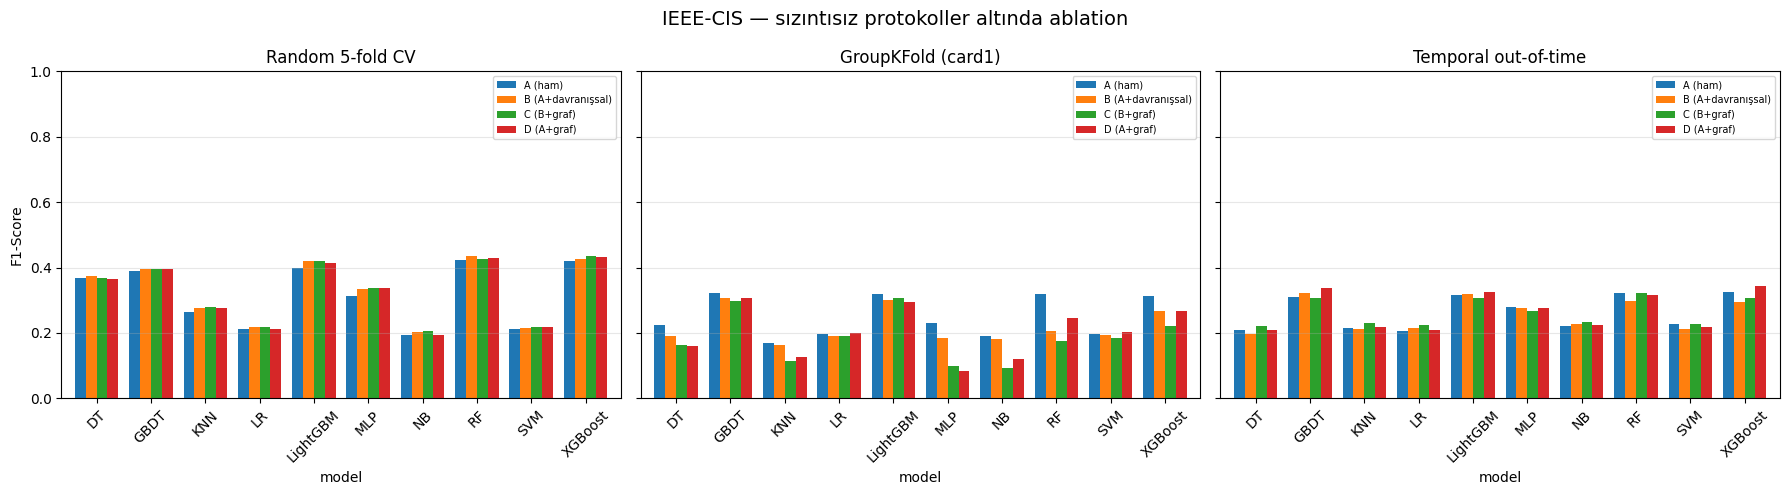

In [49]:
all_res = pd.concat([res_random, res_group, res_temporal], ignore_index=True)
all_res.to_csv('ieee_results_all_protocols.csv', index=False)

gain = []
for proto in all_res['protocol'].unique():
    s = all_res[all_res.protocol==proto]
    p = s.pivot_table(index='model', columns='feature_set', values='f1', aggfunc='mean')
    for m in p.index:
        gain.append({'protocol':proto,'model':m,
                     'B-A (davranışsal)':round(p.loc[m,'B (A+davranışsal)']-p.loc[m,'A (ham)'],4),
                     'D-A (saf graf)'   :round(p.loc[m,'D (A+graf)']-p.loc[m,'A (ham)'],4),
                     'C-B (graf net)'   :round(p.loc[m,'C (B+graf)']-p.loc[m,'B (A+davranışsal)'],4)})
gain_df = pd.DataFrame(gain)
print('='*115)
print('KATKI AYRIŞTIRMASI — hangi öznitelik grubu ne kadar katkı sağlıyor?')
print('='*115)
print(gain_df.pivot_table(index='model', columns='protocol',
      values=['B-A (davranışsal)','D-A (saf graf)','C-B (graf net)']).round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18,5), sharey=True)
for ax, proto in zip(axes, all_res['protocol'].unique()):
    s = all_res[all_res.protocol==proto]
    p = s.pivot_table(index='model', columns='feature_set', values='f1', aggfunc='mean')[order]
    p.plot(kind='bar', ax=ax, width=.8)
    ax.set_title(proto, fontsize=12); ax.set_ylabel('F1-Score'); ax.set_ylim(0,1)
    ax.legend(fontsize=7); ax.grid(axis='y', alpha=.3); ax.tick_params(axis='x', rotation=45)
plt.suptitle('IEEE-CIS — sızıntısız protokoller altında ablation', fontsize=14)
plt.tight_layout(); plt.show()

## 13. İstatistiksel Anlamlılık

In [50]:
def paired_test(res, s1, s2, metric='f1'):
    out = []
    for m in res['model'].unique():
        a = res[(res.model==m)&(res.feature_set==s1)].sort_values('fold')[metric].values
        b = res[(res.model==m)&(res.feature_set==s2)].sort_values('fold')[metric].values
        if len(a) < 2 or len(a) != len(b): continue
        d = a - b
        if np.allclose(d, 0):
            out.append({'model':m,'mean_diff':0.0,'p_ttest':1.0,'significant_p<0.05':'no'}); continue
        t_, p_ = stats.ttest_rel(a, b)
        try: _, pw = stats.wilcoxon(a, b)
        except Exception: pw = np.nan
        out.append({'model':m,'mean_diff':round(d.mean(),5),'std_diff':round(d.std(ddof=1),5),
                    't_stat':round(t_,3),'p_ttest':round(p_,4),
                    'p_wilcoxon':round(pw,4) if not np.isnan(pw) else np.nan,
                    'cohens_d':round(d.mean()/d.std(ddof=1),3) if d.std(ddof=1)>0 else np.nan,
                    'significant_p<0.05':'YES' if p_<0.05 else 'no'})
    return pd.DataFrame(out)

for res_, nm in [(res_random,'Random 5-fold'), (res_group,'GroupKFold')]:
    print('='*100); print(f'{nm}: Set C vs Set B (graf net katkısı)'); print('='*100)
    print(paired_test(res_,'C (B+graf)','B (A+davranışsal)').to_string(index=False))
    print(f'\n{nm}: Set D vs Set A (saf graf katkısı)')
    print(paired_test(res_,'D (A+graf)','A (ham)').to_string(index=False))
    print()

Random 5-fold: Set C vs Set B (graf net katkısı)
   model  mean_diff  std_diff  t_stat  p_ttest  p_wilcoxon  cohens_d significant_p<0.05
      LR    0.00027   0.00485   0.125   0.9063      0.8125     0.056                 no
      NB    0.00350   0.00127   6.146   0.0036      0.0625     2.749                YES
      DT   -0.00565   0.01049  -1.205   0.2947      0.6250    -0.539                 no
     KNN    0.00410   0.00200   4.589   0.0101      0.0625     2.052                YES
     SVM    0.00121   0.00370   0.730   0.5059      0.6250     0.326                 no
      RF   -0.00647   0.00829  -1.745   0.1560      0.1875    -0.780                 no
    GBDT    0.00067   0.00556   0.269   0.8015      0.8125     0.120                 no
 XGBoost    0.00888   0.01139   1.744   0.1561      0.3125     0.780                 no
LightGBM    0.00115   0.00747   0.345   0.7472      0.8125     0.154                 no
     MLP    0.00509   0.01602   0.711   0.5164      0.6250     0.318   

## 14. Sınıf Dengesizliği Stratejileri

In [51]:
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek

SAMPLERS = {
    'None'       : None,
    'RandomUnder': RandomUnderSampler(sampling_strategy=1/3, random_state=SEED),
    'NearMiss'   : NearMiss(version=1, sampling_strategy=1/3),
    'SMOTE'      : SMOTE(sampling_strategy=1/3, k_neighbors=5, random_state=SEED),
    'SMOTETomek' : SMOTETomek(random_state=SEED),
}
best_set = 'C (B+graf)'
rows = []
for sname, samp in SAMPLERS.items():
    print(f'  Strateji: {sname}', flush=True)
    r, _ = run_protocol(splits_random[:SAMPLING_FOLDS], df, {best_set: FEATURE_SETS[best_set]},
                        model_names=['RF'], sampler=samp,
                        label=f'sampling={sname}', tag=f'S_{sname}', verbose=False)
    agg = r[['accuracy','precision','recall','f1','auc_roc','pr_auc','mcc','fpr']].mean().round(4)
    agg['strategy'] = sname
    rows.append(agg)

samp_df = pd.DataFrame(rows).set_index('strategy')
print('='*100); print('SINIF DENGESİZLİĞİ STRATEJİLERİ (RF + Set C)'); print('='*100)
print(samp_df.to_string())
samp_df.to_csv('ieee_results_sampling.csv')

  Strateji: None
  Strateji: RandomUnder
  Strateji: NearMiss
  Strateji: SMOTE
  Strateji: SMOTETomek
SINIF DENGESİZLİĞİ STRATEJİLERİ (RF + Set C)
             accuracy  precision  recall      f1  auc_roc  pr_auc     mcc     fpr
strategy                                                                         
None           0.9585     0.4237  0.4294  0.4240   0.8743  0.4117  0.4039  0.0220
RandomUnder    0.8830     0.1882  0.6870  0.2950   0.8709  0.3493  0.3179  0.1098
NearMiss       0.2470     0.0343  0.7448  0.0656   0.5061  0.0516 -0.0116  0.7713
SMOTE          0.9380     0.2931  0.5264  0.3764   0.8539  0.3489  0.3632  0.0468
SMOTETomek     0.9047     0.2075  0.5976  0.3080   0.8454  0.2968  0.3136  0.0840


## 15. En İyi Modelin Detaylı Analizi (zamansal protokol)

In [52]:
best_model_name = p3['C (B+graf)'].idxmax()
print(f'Zamansal protokolde en iyi model: {best_model_name}')

d_tr, d_te = df[df.TransactionDT<=TEMPORAL_CUT], df[df.TransactionDT>TEMPORAL_CUT]
f_tr, f_te, tinfo_best = compute_fold_features(d_tr, d_te)
y_tr, y_te = f_tr['isFraud'].values, f_te['isFraud'].values

feats_C = [c for c in FEATURE_SETS['C (B+graf)'] if c in f_tr.columns]
Xtr = np.nan_to_num(f_tr[feats_C].astype(np.float64).values, nan=0.0, posinf=0.0, neginf=0.0)
Xte = np.nan_to_num(f_te[feats_C].astype(np.float64).values, nan=0.0, posinf=0.0, neginf=0.0)

# Eşik seçimi dahil tüm adımlar fit_predict içinde, yalnızca eğitim verisinden
best_model = get_models()[best_model_name]
yp, ys, fit_s, best_thr = fit_predict(best_model, Xtr, y_tr, Xte,
                                      model_name=best_model_name)

print(f'Eğitim fold\'unda seçilen eşik: {best_thr:.4f}  (sabit 0.5 yerine)')
print(f'Eğitim süresi: {fit_s:.1f}s')

print('\n' + classification_report(y_te, yp, target_names=['Normal','Fraud'], digits=4))
met = full_metrics(y_te, yp, ys)
for k, v in met.items():
    print(f'  {k:22s}: {v:.4f}' if isinstance(v, float) else f'  {k:22s}: {v}')

# Karşılaştırma: sabit 0.5 eşiği ne verirdi?
yp_fixed = (ys >= 0.5).astype(int)
met_fixed = full_metrics(y_te, yp_fixed, ys)
print('\n' + '='*70)
print('EŞİK SEÇİMİNİN ETKİSİ')
print('='*70)
cmp_thr = pd.DataFrame({
    'Sabit 0.5':      {k: round(met_fixed[k],4) for k in ['precision','recall','f1','mcc','fpr']},
    f'Seçilen {best_thr:.3f}': {k: round(met[k],4) for k in ['precision','recall','f1','mcc','fpr']},
})
print(cmp_thr.to_string())
print('\nNOT: AUC-ROC ve PR-AUC eşikten bağımsızdır, değişmez.')
print(f'  AUC-ROC={met["auc_roc"]:.4f}  PR-AUC={met["pr_auc"]:.4f}')

Zamansal protokolde en iyi model: RF
    graf=0.6s cent=47.5s uygula=4.5s | düğüm=9,401 kenar=42,501 topluluk=18 görülmeyen kart=%2.4
Eğitim fold'unda seçilen eşik: 0.1756  (sabit 0.5 yerine)
Eğitim süresi: 44.7s

              precision    recall  f1-score   support

      Normal     0.9744    0.9786    0.9765     38575
       Fraud     0.3431    0.3032    0.3219      1425

    accuracy                         0.9545     40000
   macro avg     0.6587    0.6409    0.6492     40000
weighted avg     0.9519    0.9545    0.9531     40000

  accuracy              : 0.9545
  precision             : 0.3431
  recall                : 0.3032
  f1                    : 0.3219
  auc_roc               : 0.8348
  pr_auc                : 0.2522
  mcc                   : 0.2991
  fpr                   : 0.0214
  precision_at_1pct     : 0.4625
  recall_at_1pct        : 0.1298
  tn                    : 37748
  fp                    : 827
  fn                    : 993
  tp                    : 432

EŞİK S

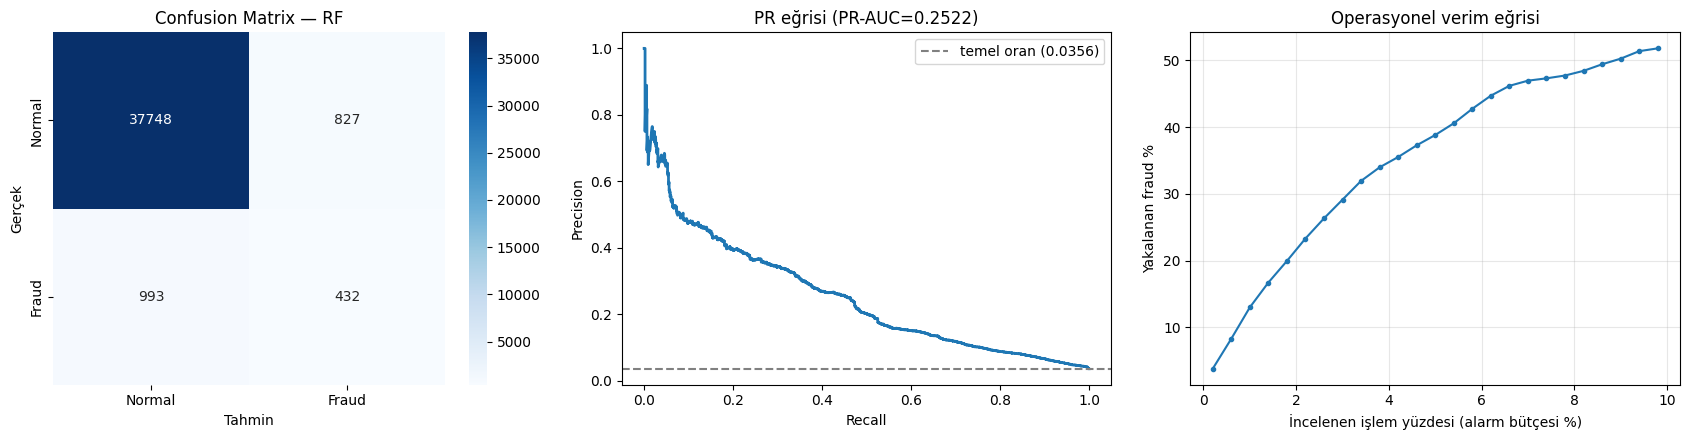

In [53]:
fig, ax = plt.subplots(1, 3, figsize=(17,4.5))

cm = confusion_matrix(y_te, yp)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=['Normal','Fraud'], yticklabels=['Normal','Fraud'])
ax[0].set_title(f'Confusion Matrix — {best_model_name}')
ax[0].set_xlabel('Tahmin'); ax[0].set_ylabel('Gerçek')

prec, rec, _ = precision_recall_curve(y_te, ys)
ax[1].plot(rec, prec, lw=2)
ax[1].axhline(y_te.mean(), ls='--', c='gray', label=f'temel oran ({y_te.mean():.4f})')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
ax[1].set_title(f'PR eğrisi (PR-AUC={met["pr_auc"]:.4f})'); ax[1].legend()

ks = np.arange(0.002, 0.101, 0.004)
caught = [y_te[np.argsort(-ys)[:max(1,int(len(y_te)*k))]].sum()/y_te.sum() for k in ks]
ax[2].plot(ks*100, np.array(caught)*100, marker='o', ms=3)
ax[2].set_xlabel('İncelenen işlem yüzdesi (alarm bütçesi %)')
ax[2].set_ylabel('Yakalanan fraud %')
ax[2].set_title('Operasyonel verim eğrisi'); ax[2].grid(alpha=.3)

plt.tight_layout(); plt.show()

## 16. SHAP — Kategori Bazında Katkı

SHAP modeli: RF

En önemli 15 öznitelik:
           feature  mean_abs_shap         category
 R_emaildomain_enc       0.006789          Raw (A)
                D3       0.006099          Raw (A)
     ProductCD_enc       0.005719          Raw (A)
                D2       0.004794          Raw (A)
             card3       0.004352          Raw (A)
    addr1_pagerank       0.003521      Graph (C\B)
    TransactionAmt       0.003428          Raw (A)
amount_to_addr_avg       0.003276 Behavioral (B\A)
TransactionAmt_log       0.003083          Raw (A)
      addr1_degree       0.002868      Graph (C\B)
   card_avg_amount       0.002687 Behavioral (B\A)
         card6_enc       0.002670          Raw (A)
               D15       0.002627          Raw (A)
 addr1_betweenness       0.002596      Graph (C\B)
 P_emaildomain_enc       0.001905          Raw (A)

KATEGORİ BAZINDA SHAP KATKI PAYI
                      sum  count  share_%
category                                 
Behavioral (B\A)  0.01748

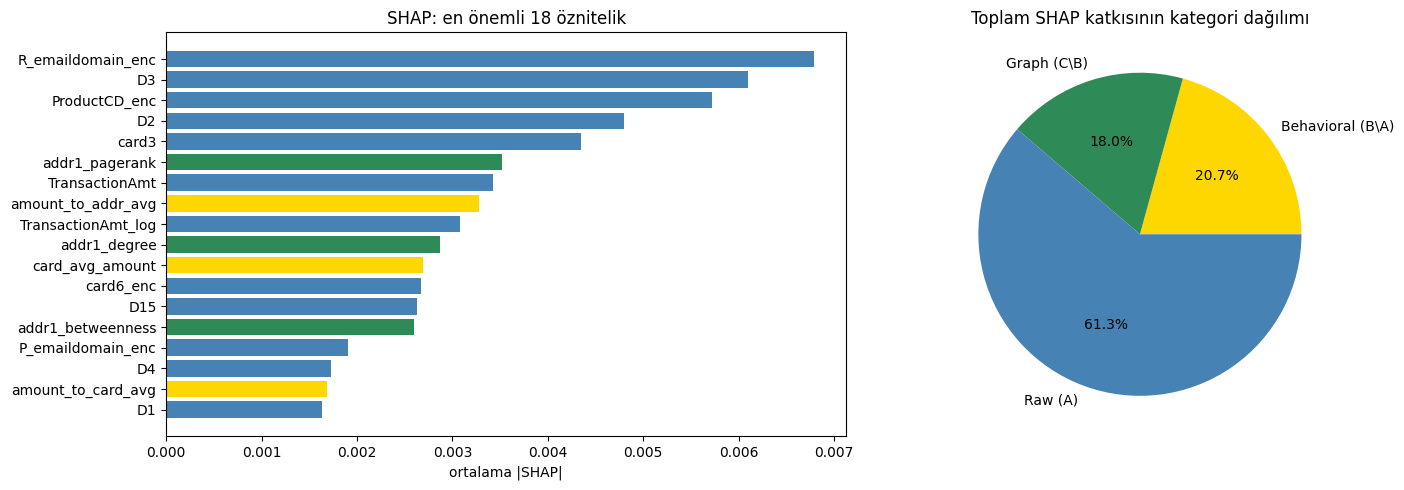

In [54]:
try:
    import shap
    shap_model = best_model_name if best_model_name in ['RF','XGBoost','LightGBM','GBDT','DT'] else 'LightGBM'
    print(f'SHAP modeli: {shap_model}')
    m = get_models()[shap_model]; m.fit(Xtr_s, y_tr)

    n_s = min(5000, len(Xte_s))
    idx = np.random.RandomState(SEED).choice(len(Xte_s), n_s, replace=False)
    sv = shap.TreeExplainer(m).shap_values(Xte_s[idx])
    if isinstance(sv, list): sv = sv[1]
    if sv.ndim == 3: sv = sv[:,:,1]

    imp = pd.DataFrame({'feature':feats_C, 'mean_abs_shap':np.abs(sv).mean(axis=0)})
    def _cat(f):
        if f in BEHAVIORAL:   return 'Behavioral (B\\A)'
        if f in GRAPH_FEATS:  return 'Graph (C\\B)'
        return 'Raw (A)'
    imp['category'] = imp['feature'].map(_cat)
    imp = imp.sort_values('mean_abs_shap', ascending=False)
    print('\nEn önemli 15 öznitelik:'); print(imp.head(15).to_string(index=False))

    ct = imp.groupby('category')['mean_abs_shap'].agg(['sum','count'])
    ct['share_%'] = (ct['sum']/ct['sum'].sum()*100).round(2)
    print('\n' + '='*70); print('KATEGORİ BAZINDA SHAP KATKI PAYI'); print('='*70)
    print(ct.round(5).to_string())
    print('\nKARŞILAŞTIRMA — BankSim: Graph %67.0, Behavioral %19.2, Raw %13.8')
    imp.to_csv('ieee_shap_importance.csv', index=False)

    fig, ax = plt.subplots(1, 2, figsize=(15,5))
    colors = {'Raw (A)':'steelblue','Behavioral (B\\A)':'gold','Graph (C\\B)':'seagreen'}
    top = imp.head(18).iloc[::-1]
    ax[0].barh(top['feature'], top['mean_abs_shap'], color=[colors[c] for c in top['category']])
    ax[0].set_title('SHAP: en önemli 18 öznitelik'); ax[0].set_xlabel('ortalama |SHAP|')
    ax[1].pie(ct['sum'], labels=ct.index, autopct='%1.1f%%',
              colors=[colors[c] for c in ct.index])
    ax[1].set_title('Toplam SHAP katkısının kategori dağılımı')
    plt.tight_layout(); plt.show()
except ImportError:
    print('shap kurulu değil: pip install shap')

## 17. Hesaplama Maliyeti

"Graf öznitelik mühendisliği GNN'e göre hızlıdır" iddiasının ölçümle
desteklenmesi

In [55]:
tim_all = pd.concat([tim_random.assign(protocol='Random 5-fold'),
                     tim_group.assign(protocol='GroupKFold'),
                     tim_temporal.assign(protocol='Temporal')], ignore_index=True)

summ = tim_all.groupby('protocol')[['graph_build_s','centrality_s','apply_s',
                                    'n_nodes','n_edges','n_communities',
                                    'unseen_card_frac']].mean().round(3)
print('='*95); print('GRAF ÖZNİTELİK ÇIKARIM MALİYETİ'); print('='*95)
print(summ.to_string())

alg_cols = [c for c in tim_all.columns if c.startswith('alg_') and c.endswith('_s')]
per_alg = tim_all[alg_cols].mean().round(3).sort_values(ascending=False)
per_alg.index = [c[4:-2] for c in per_alg.index]
print('\nAlgoritma bazlı ortalama süre (saniye):'); print(per_alg.to_string())

total_extract = float(summ[['graph_build_s','centrality_s','apply_s']].sum(axis=1).mean())
print(f'\nToplam çıkarım süresi : {total_extract:.2f} s')
print(f'İşlem sayısı          : {len(df):,}')
print(f'Verim                 : {len(df)/total_extract:,.0f} işlem/saniye')
print(f'İşlem başına maliyet  : {total_extract/len(df)*1e6:.2f} mikrosaniye')
print('\nKARŞILAŞTIRMA — BankSim: 12.049 işlem/saniye')

fit_summ = all_res.groupby(['model','feature_set'])['fit_s'].mean().unstack().round(2)
print('\nModel eğitim süreleri (saniye):'); print(fit_summ.to_string())

json.dump({'feature_extraction':summ.to_dict(),'per_algorithm_s':per_alg.to_dict(),
           'total_extract_s':total_extract,'tx_per_second':len(df)/total_extract,
           'fast_mode':FAST_MODE,'subsample_n':SUBSAMPLE_N,'knn_cap':KNN_TRAIN_CAP,
           'hyperparameters':HYPERPARAMS},
          open('ieee_timing_analysis.json','w'), indent=2, default=str)
print('\nieee_timing_analysis.json kaydedildi.')

GRAF ÖZNİTELİK ÇIKARIM MALİYETİ
               graph_build_s  centrality_s  apply_s  n_nodes  n_edges  n_communities  unseen_card_frac
protocol                                                                                              
GroupKFold             0.746        37.518    2.850   8164.6  37708.0           17.4             1.000
Random 5-fold          0.892        46.923    3.767   9409.2  42353.4           17.6             0.020
Temporal               1.034        46.408    2.945   9401.0  42501.0           18.0             0.024

Algoritma bazlı ortalama süre (saniye):
betweenness    29.452
clustering     11.358
louvain         1.566
pagerank        0.167
degree          0.041
eigenvector     0.018

Toplam çıkarım süresi : 47.69 s
İşlem sayısı          : 200,000
Verim                 : 4,193 işlem/saniye
İşlem başına maliyet  : 238.47 mikrosaniye

KARŞILAŞTIRMA — BankSim: 12.049 işlem/saniye

Model eğitim süreleri (saniye):
feature_set  A (ham)  A+VestaC (referans)  B (A+da

## 18. Makale Tabloları ve Özet

In [56]:
tables = {
    'T1_feature_categories': feature_map_df.groupby(['Category','Present in sets']).size().reset_index(name='# features'),
    'T2_audit_single_feat' : scan.head(20),
    'T3_audit_rules'       : rule_df,
    'T4_audit_degenerate'  : deg_df,
    'T5_audit_vesta_overlap': overlap_df,
    'T6_sampling'          : samp_df,
    'T7_random_cv'         : p1,
    'T8_groupkfold'        : p2,
    'T9_temporal'          : p3,
    'T10_significance_CB'  : paired_test(res_random,'C (B+graf)','B (A+davranışsal)'),
    'T11_significance_DA'  : paired_test(res_random,'D (A+graf)','A (ham)'),
    'T12_timing'           : summ,
}
with pd.ExcelWriter('paper_tables_ieee.xlsx') as w:
    for n, t in tables.items():
        t.to_excel(w, sheet_name=n[:31])
print('paper_tables_ieee.xlsx kaydedildi.\n')

print('='*100); print('IEEE-CIS — ANA BULGULAR (sızıntısız)'); print('='*100)
print(f'''
VERİ
  İşlem      : {len(df):,} (prevalans korundu: %{df['isFraud'].mean()*100:.3f})
  Graf       : {summ['n_nodes'].mean():,.0f} düğüm, {summ['n_edges'].mean():,.0f} kenar
  Kenar tanımı: {GRAPH_RELATIONS}

ARTEFAKT DENETİMİ
  En yüksek tek öznitelik AUC : {scan.iloc[0]['auc']:.4f} ({scan.iloc[0]['feature']})
  En iyi basit kural F1       : {rule_df['F1'].max():.4f}
  (PaySim referans: kural F1=0.9890 -> reddedilmişti)
''')
for nm, p in [('Rastgele 5-fold CV', p1), ('GroupKFold (card1)', p2), ('Zamansal', p3)]:
    bm = p['C (B+graf)'].idxmax()
    print(f'{nm}:')
    print(f'  En iyi model / F1    : {bm} / {p.loc[bm,"C (B+graf)"]:.4f}')
    print(f'  Ortalama B-A         : {(p["B (A+davranışsal)"]-p["A (ham)"]).mean():+.4f}')
    print(f'  Ortalama D-A (graf)  : {p["D-A"].mean():+.4f}')
    print(f'  Ortalama C-B (graf)  : {p["C-B"].mean():+.4f}')
    print()
print(f'Hesaplama: {total_extract:.1f}s çıkarım, {len(df)/total_extract:,.0f} işlem/saniye')

paper_tables_ieee.xlsx kaydedildi.

IEEE-CIS — ANA BULGULAR (sızıntısız)

VERİ
  İşlem      : 200,000 (prevalans korundu: %3.550)
  Graf       : 8,992 düğüm, 40,854 kenar
  Kenar tanımı: [('card1', 'addr1'), ('card1', 'P_emaildomain')]

ARTEFAKT DENETİMİ
  En yüksek tek öznitelik AUC : 0.6913 (C4)
  En iyi basit kural F1       : 0.1797
  (PaySim referans: kural F1=0.9890 -> reddedilmişti)

Rastgele 5-fold CV:
  En iyi model / F1    : XGBoost / 0.4352
  Ortalama B-A         : +0.0102
  Ortalama D-A (graf)  : +0.0082
  Ortalama C-B (graf)  : +0.0013

GroupKFold (card1):
  En iyi model / F1    : LightGBM / 0.3062
  Ortalama B-A         : -0.0291
  Ortalama D-A (graf)  : -0.0471
  Ortalama C-B (graf)  : -0.0339

Zamansal:
  En iyi model / F1    : RF / 0.3219
  Ortalama B-A         : -0.0057
  Ortalama D-A (graf)  : +0.0047
  Ortalama C-B (graf)  : +0.0069

Hesaplama: 47.7s çıkarım, 4,193 işlem/saniye
